In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import wandb
from datasets import get_dataset
import torch
from utils import save_run, load_run
from funcs import train_epoch, val_epoch, test_epoch
from weight_inits import init_timesformer
from torch.utils.data import DataLoader
from models.vivit_custom.utils.scheduler import WarmupCosineSchedule
from transforms import get_transforms, Div255, SplitEqually

from constants import get_classes
from transformers import TimesformerConfig, TimesformerForVideoClassification
from transformers import ViTForImageClassification
from pytorchvideo.transforms import MixUp
import torch
from torchvision.transforms.v2 import (
    ScaleJitter,
    RandAugment,
    RandomCrop,
    Compose,
    ColorJitter,
    RandomHorizontalFlip,
    Normalize,
    RandomApply,
    UniformTemporalSubsample,
    CenterCrop,
    Lambda,
)
from pytorchvideo.transforms import UniformTemporalSubsample, ApplyTransformToKey

C:\Users\Wojtek\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
config = {
    "base_learning_rate": 0.001,
    "label_smoothing": 0.2,
    "epochs": 10,
    "frames": 8,
    "val_epochs": 1,
    "batch_size": 20,
    "weight_decay": 1e-5,
    "load_run": False,
    "init_vit": True,
    "vit_base_size": "tiny",
    "cosine_schedule": True,
    "augmentations": True,
    "advanced_augmentations": True,
    "mixup": True,
    "mixup_alpha": 0.2,
    "dataset": "ucf101",
}

In [ ]:
CLASSES_LIST = get_classes(config["dataset"])

ds_transform_train, ds_transform_valid, test_transform = get_transforms(config, CLASSES_LIST, config['dataset'])

dataset_train, dataset_valid, dataset_test, num_labels = get_dataset(
    config["dataset"], ds_transform_train, ds_transform_valid, test_transform, lazy=False
)

#training_loader = DataLoader(dataset=dataset_train, batch_size=8, shuffle=True)

In [ ]:
transform = Compose(
    transforms=[
        UniformTemporalSubsample(num_samples=config["frames"], temporal_dim=0),
        RandomHorizontalFlip(p=0.5),
        #ScaleJitter(target_size=(240, 320), scale_range=(0.85, 1.33)),
        RandomCrop(size=(224, 224), pad_if_needed=True, fill=128),
        RandomApply(p=1, transforms=[ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.1)]),
        # RandAugment(num_ops=2, magnitude=10, fill=128),
        Div255(),
        Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ]
)

In [77]:
from utils import show_img_chw

In [78]:
dataset_valid.transform = transform

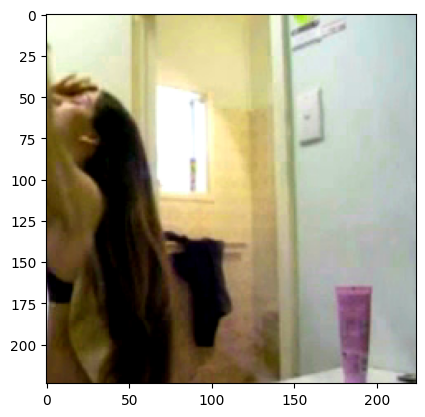

In [83]:
show_img_chw(dataset_valid[0][0][0], denormalize=True)